In [1]:
import requests 
from bs4 import BeautifulSoup
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time

print("All libraries loaded!")

All libraries loaded!


In [3]:
url = "https://books.toscrape.com/catalogue/page-1.html"
response = requests.get(url)
soup = BeautifulSoup(response.text, "html.parser")

#find all the book cards on the page
books = soup.find_all("article", class_="product_pod")
print("Number of books on the page:", len(books))

#look at the first book
first_book = books[0]
print(first_book.prettify()[:1500])

Number of books on the page: 20
<article class="product_pod">
 <div class="image_container">
  <a href="a-light-in-the-attic_1000/index.html">
   <img alt="A Light in the Attic" class="thumbnail" src="../media/cache/2c/da/2cdad67c44b002e7ead0cc35693c0e8b.jpg"/>
  </a>
 </div>
 <p class="star-rating Three">
  <i class="icon-star">
  </i>
  <i class="icon-star">
  </i>
  <i class="icon-star">
  </i>
  <i class="icon-star">
  </i>
  <i class="icon-star">
  </i>
 </p>
 <h3>
  <a href="a-light-in-the-attic_1000/index.html" title="A Light in the Attic">
   A Light in the ...
  </a>
 </h3>
 <div class="product_price">
  <p class="price_color">
   Â£51.77
  </p>
  <p class="instock availability">
   <i class="icon-ok">
   </i>
   In stock
  </p>
  <form>
   <button class="btn btn-primary btn-block" data-loading-text="Adding..." type="submit">
    Add to basket
   </button>
  </form>
 </div>
</article>



In [5]:
book = books[0]

title = book.h3.a["title"]
print("Title:", title)

price_text = book.find("p", class_="price_color").text
print("Raw price text:", price_text)

rating_class = book.find("p", class_="star-rating")["class"]
print("Rating class:", rating_class)

availability = book.find("p", class_="instock availability").text.strip()
print("Availability:", availability)

Title: A Light in the Attic
Raw price text: Â£51.77
Rating class: ['star-rating', 'Three']
Availability: In stock


In [6]:
#clean price
price_clean = price_text.replace("Â", "").replace("£", "")
price = float(price_clean)
print("Clean price:", price)

rating_words = {"One": 1, "Two": 2, "Three": 3, "Four": 4, "Five": 5}
rating = rating_words[rating_class[1]]
print("Numeric rating:", rating)

Clean price: 51.77
Numeric rating: 3


In [8]:
all_books = []

for page_num in range(1, 51): #this is pages 1 to 50
    url = f"https://books.toscrape.com/catalogue/page-{page_num}.html"
    response = requests.get(url)
    soup = BeautifulSoup(response.text, "html.parser")
    books_on_page = soup.find_all("article", class_="product_pod")

    for book in books_on_page:
        title = book.h3.a["title"]

        price_text = book.find("p", class_="price_color").text
        price = float(price_text.replace("Â", "").replace("£", ""))

        rating_class = book.find("p", class_="star-rating")["class"]
        rating = rating_words[rating_class[1]]
        
        availability = book.find("p", class_="instock availability").text.strip()
        
        #store everything
        all_books.append({
            "title": title,
            "price_gbp": price,
            "rating": rating,
            "availability": availability
        })
    
    print(f"Done page {page_num} - total books so far: {len(all_books)}")
    time.sleep(0.3)

print(f"\nFINISHED! Scraped {len(all_books)} books total")

Done page 1 - total books so far: 20
Done page 2 - total books so far: 40
Done page 3 - total books so far: 60
Done page 4 - total books so far: 80
Done page 5 - total books so far: 100
Done page 6 - total books so far: 120
Done page 7 - total books so far: 140
Done page 8 - total books so far: 160
Done page 9 - total books so far: 180
Done page 10 - total books so far: 200
Done page 11 - total books so far: 220
Done page 12 - total books so far: 240
Done page 13 - total books so far: 260
Done page 14 - total books so far: 280
Done page 15 - total books so far: 300
Done page 16 - total books so far: 320
Done page 17 - total books so far: 340
Done page 18 - total books so far: 360
Done page 19 - total books so far: 380
Done page 20 - total books so far: 400
Done page 21 - total books so far: 420
Done page 22 - total books so far: 440
Done page 23 - total books so far: 460
Done page 24 - total books so far: 480
Done page 25 - total books so far: 500
Done page 26 - total books so far: 520

In [10]:
df = pd.DataFrame(all_books)

print(df.shape)  # should print (1000, 4)
print(df.head())  # peek at the first 5 rows

#Save to CSV
df.to_csv("books_raw.csv", index=False)
print("Saved books_raw.csv")

(1000, 4)
                                   title  price_gbp  rating availability
0                   A Light in the Attic      51.77       3     In stock
1                     Tipping the Velvet      53.74       1     In stock
2                             Soumission      50.10       1     In stock
3                          Sharp Objects      47.82       4     In stock
4  Sapiens: A Brief History of Humankind      54.23       5     In stock
Saved books_raw.csv


In [12]:
print("Shape:", df.shape)
print("\nColumn types:\n", df.dtypes)
print("\nMissing values:\n", df.isnull().sum())
print("\nPrice stats:\n", df["price_gbp"].describe())
print("\nRating counts:\n", df["rating"].value_counts().sort_index())
print("\nAvailability sample:\n", df["availability"].head(10))

Shape: (1000, 4)

Column types:
 title               str
price_gbp       float64
rating            int64
availability        str
dtype: object

Missing values:
 title           0
price_gbp       0
rating          0
availability    0
dtype: int64

Price stats:
 count    1000.00000
mean       35.07035
std        14.44669
min        10.00000
25%        22.10750
50%        35.98000
75%        47.45750
max        59.99000
Name: price_gbp, dtype: float64

Rating counts:
 rating
1    226
2    196
3    203
4    179
5    196
Name: count, dtype: int64

Availability sample:
 0    In stock
1    In stock
2    In stock
3    In stock
4    In stock
5    In stock
6    In stock
7    In stock
8    In stock
9    In stock
Name: availability, dtype: str


In [13]:
#create a clean copy
clean = df.copy()

#extract "In stock" as a yes/no flag
clean["in_stock"] = clean["availability"].str.contains("In stock").astype(int)

import re

def extract_quantity(text):
    match = re.search(r"\((\d+) available\)", text)
    if match:
        return int(match.group(1))
    return 0

clean["quantity"] = clean["availability"].apply(extract_quantity)

print(clean[["availability", "in_stock", "quantity"]].head(10))
print("\nSummary:")
print(clean[["price_gbp", "rating", "in_stock", "quantity"]].describe())

  availability  in_stock  quantity
0     In stock         1         0
1     In stock         1         0
2     In stock         1         0
3     In stock         1         0
4     In stock         1         0
5     In stock         1         0
6     In stock         1         0
7     In stock         1         0
8     In stock         1         0
9     In stock         1         0

Summary:
        price_gbp       rating  in_stock  quantity
count  1000.00000  1000.000000    1000.0    1000.0
mean     35.07035     2.923000       1.0       0.0
std      14.44669     1.434967       0.0       0.0
min      10.00000     1.000000       1.0       0.0
25%      22.10750     2.000000       1.0       0.0
50%      35.98000     3.000000       1.0       0.0
75%      47.45750     4.000000       1.0       0.0
max      59.99000     5.000000       1.0       0.0


In [14]:
clean_final = clean[["title", "price_gbp", "rating", "in_stock", "quantity"]]
clean_final.to_csv("books_clean.csv", index=False)
print("Saved books_clean.csv")

Saved books_clean.csv


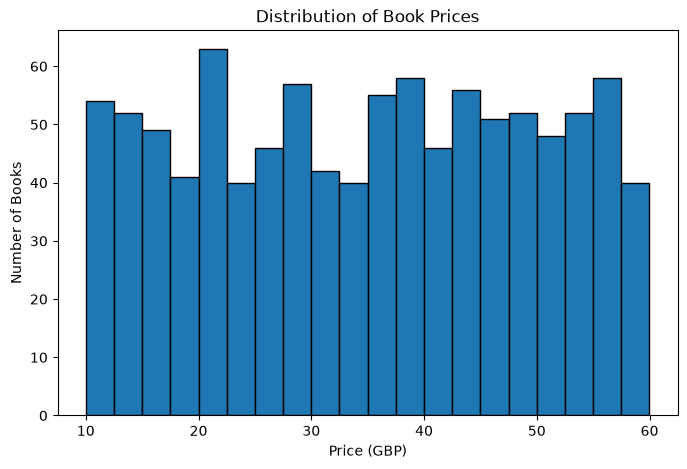

In [15]:
plt.figure(figsize=(8, 5))
plt.hist(clean_final["price_gbp"], bins=20, edgecolor="black")
plt.title("Distribution of Book Prices")
plt.xlabel("Price (GBP)")
plt.ylabel("Number of Books")
plt.show()

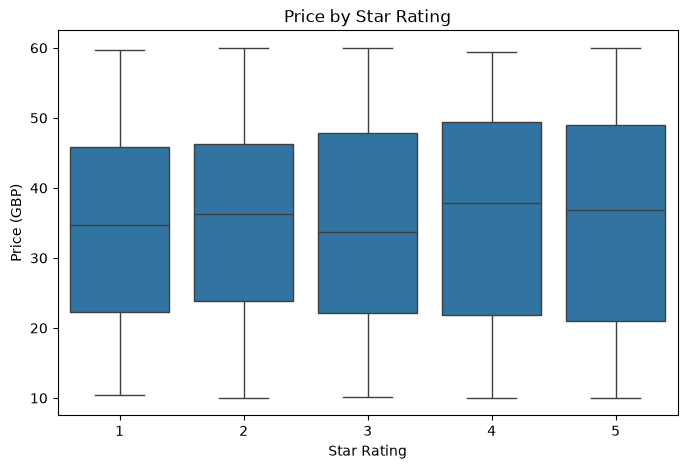

In [16]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=clean_final, x="rating", y="price_gbp")
plt.title("Price by Star Rating")
plt.xlabel("Star Rating")
plt.ylabel("Price (GBP)")
plt.show()

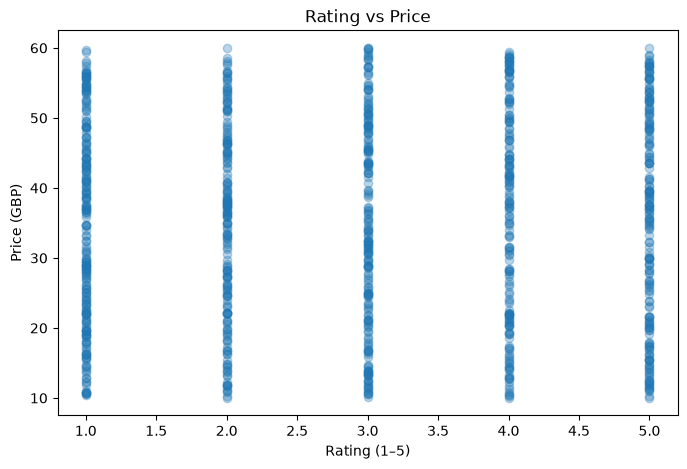

In [17]:
plt.figure(figsize=(8, 5))
plt.scatter(clean_final["rating"], clean_final["price_gbp"], alpha=0.3)
plt.title("Rating vs Price")
plt.xlabel("Rating (1–5)")
plt.ylabel("Price (GBP)")
plt.show()

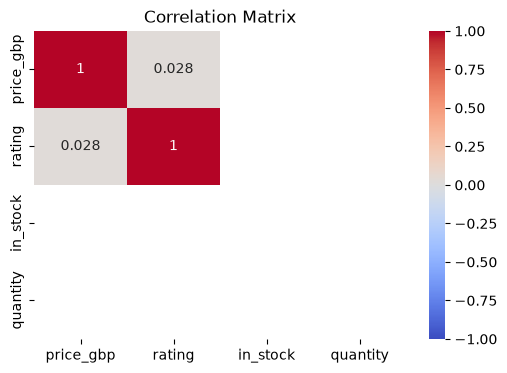

In [18]:
plt.figure(figsize=(6, 4))
sns.heatmap(clean_final[["price_gbp", "rating", "in_stock", "quantity"]].corr(),
            annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation Matrix")
plt.show()

In [19]:
from sklearn.model_selection import train_test_split

X = clean_final[["rating", "in_stock", "quantity"]]
y = clean_final["price_gbp"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training set size:", len(X_train))
print("Test set size:", len(X_test))


Training set size: 800
Test set size: 200


In [20]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train, y_train)

print("Coefficients:")
for name, coef in zip(X.columns, model.coef_):
    print(f"  {name}: {coef:.4f}")
print(f"Intercept: {model.intercept_:.4f}")

Coefficients:
  rating: 0.3601
  in_stock: 0.0000
  quantity: 0.0000
Intercept: 34.2345


In [21]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"MAE:  {mae:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"R²:   {r2:.4f}")

MAE:  12.66
RMSE: 14.54
R²:   -0.0066
